In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
df=pd.read_csv('synthetic_stroke_balanced.csv')
df

,patient_id,age,gender,systolic_bp,diastolic_bp,hypertension,avg_glucose_level,diabetes,bmi,cholesterol,heart_disease,atrial_fibrillation,smoking_status,alcohol_consumption,physical_activity,family_history_stroke,work_type,residence_type,stroke
0,100001,62,Male,126,69,0,102.0,0,24.3,216.0,0,0,Never,Moderate,High,0,Self-employed,Urban,1
1,100002,21,Female,119,63,1,93.0,0,15.0,136.0,0,0,Current,Non-drinker,High,0,Student,Rural,0
2,100003,84,Male,155,83,0,104.9,0,21.2,252.0,0,0,Former,Non-drinker,High,0,Retired,Urban,1
3,100004,60,Female,120,74,0,133.3,1,37.8,156.0,1,0,Former,Heavy,Low,1,Self-employed,Urban,1
4,100005,28,Male,107,75,0,109.6,0,24.2,161.0,0,0,Never,Heavy,Moderate,1,Private,Rural,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5195,105196,77,Male,131,90,1,87.2,0,25.6,224.0,0,0,Former,Moderate,Low,1,Self-employed,Rural,1
5196,105197,51,Male,150,76,1,153.5,1,27.9,213.0,1,1,Current,Moderate,Moderate,0,Private,Urban,1
5197,105198,56,Female,129,72,0,93.5,0,28.8,169.0,0,0,Former,Moderate,Moderate,0,Self-employed,Rural,1
5198,105199,71,Female,126,69,0,85.7,0,21.8,165.0,0,0,Never,Moderate,Moderate,0,Retired,Urban,0


In [32]:
df.isna().sum()

patient_id                 0
age                        0
gender                     0
systolic_bp                0
diastolic_bp               0
hypertension               0
avg_glucose_level          0
diabetes                   0
bmi                      173
cholesterol              129
heart_disease              0
atrial_fibrillation        0
smoking_status             0
alcohol_consumption        0
physical_activity          0
family_history_stroke      0
work_type                  0
residence_type             0
stroke                     0
dtype: int64

In [33]:
print(df.shape)


(5200, 19)


In [34]:
df.info()
              

<class 'pandas.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   patient_id             5200 non-null   int64  
 1   age                    5200 non-null   int64  
 2   gender                 5200 non-null   str    
 3   systolic_bp            5200 non-null   int64  
 4   diastolic_bp           5200 non-null   int64  
 5   hypertension           5200 non-null   int64  
 6   avg_glucose_level      5200 non-null   float64
 7   diabetes               5200 non-null   int64  
 8   bmi                    5027 non-null   float64
 9   cholesterol            5071 non-null   float64
 10  heart_disease          5200 non-null   int64  
 11  atrial_fibrillation    5200 non-null   int64  
 12  smoking_status         5200 non-null   str    
 13  alcohol_consumption    5200 non-null   str    
 14  physical_activity      5200 non-null   str    
 15  family_history_

In [35]:
df.head()


,patient_id,age,gender,systolic_bp,diastolic_bp,hypertension,avg_glucose_level,diabetes,bmi,cholesterol,heart_disease,atrial_fibrillation,smoking_status,alcohol_consumption,physical_activity,family_history_stroke,work_type,residence_type,stroke
0,100001,62,Male,126,69,0,102.0,0,24.3,216.0,0,0,Never,Moderate,High,0,Self-employed,Urban,1
1,100002,21,Female,119,63,1,93.0,0,15.0,136.0,0,0,Current,Non-drinker,High,0,Student,Rural,0
2,100003,84,Male,155,83,0,104.9,0,21.2,252.0,0,0,Former,Non-drinker,High,0,Retired,Urban,1
3,100004,60,Female,120,74,0,133.3,1,37.8,156.0,1,0,Former,Heavy,Low,1,Self-employed,Urban,1
4,100005,28,Male,107,75,0,109.6,0,24.2,161.0,0,0,Never,Heavy,Moderate,1,Private,Rural,0


In [36]:
df.describe().T                       


,count,mean,std,min,25%,50%,75%,max
patient_id,5200.0,102600.500000,1501.255031,100001.0,101300.75,102600.5,103900.250,105200.0
age,5200.0,56.861346,16.906604,18.0,45.00,59.0,69.000,95.0
systolic_bp,5200.0,125.415769,15.827833,90.0,114.00,126.0,137.000,176.0
diastolic_bp,5200.0,72.821923,8.978668,55.0,67.00,73.0,79.000,104.0
hypertension,5200.0,0.253269,0.434926,0.0,0.00,0.0,1.000,1.0
avg_glucose_level,5200.0,113.326962,39.907691,60.0,88.90,99.7,117.325,320.0
diabetes,5200.0,0.230000,0.420873,0.0,0.00,0.0,0.000,1.0
bmi,5027.0,25.545395,4.683595,15.0,22.30,25.5,28.700,41.4
cholesterol,5071.0,192.538158,31.826974,110.0,171.00,193.0,215.000,312.0
heart_disease,5200.0,0.130000,0.336336,0.0,0.00,0.0,0.000,1.0


In [37]:
print(df.describe(include='object').T) 

                    count unique          top  freq
gender               5200      2       Female  2636
smoking_status       5200      3        Never  2387
alcohol_consumption  5200      3  Non-drinker  2060
physical_activity    5200      3          Low  1884
work_type            5200      6      Private  1966
residence_type       5200      2        Urban  2736


C:\Users\bount\AppData\Local\Temp\ipykernel_23044\3233660312.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include='object').T)


In [38]:
print(df.duplicated().sum())   

0


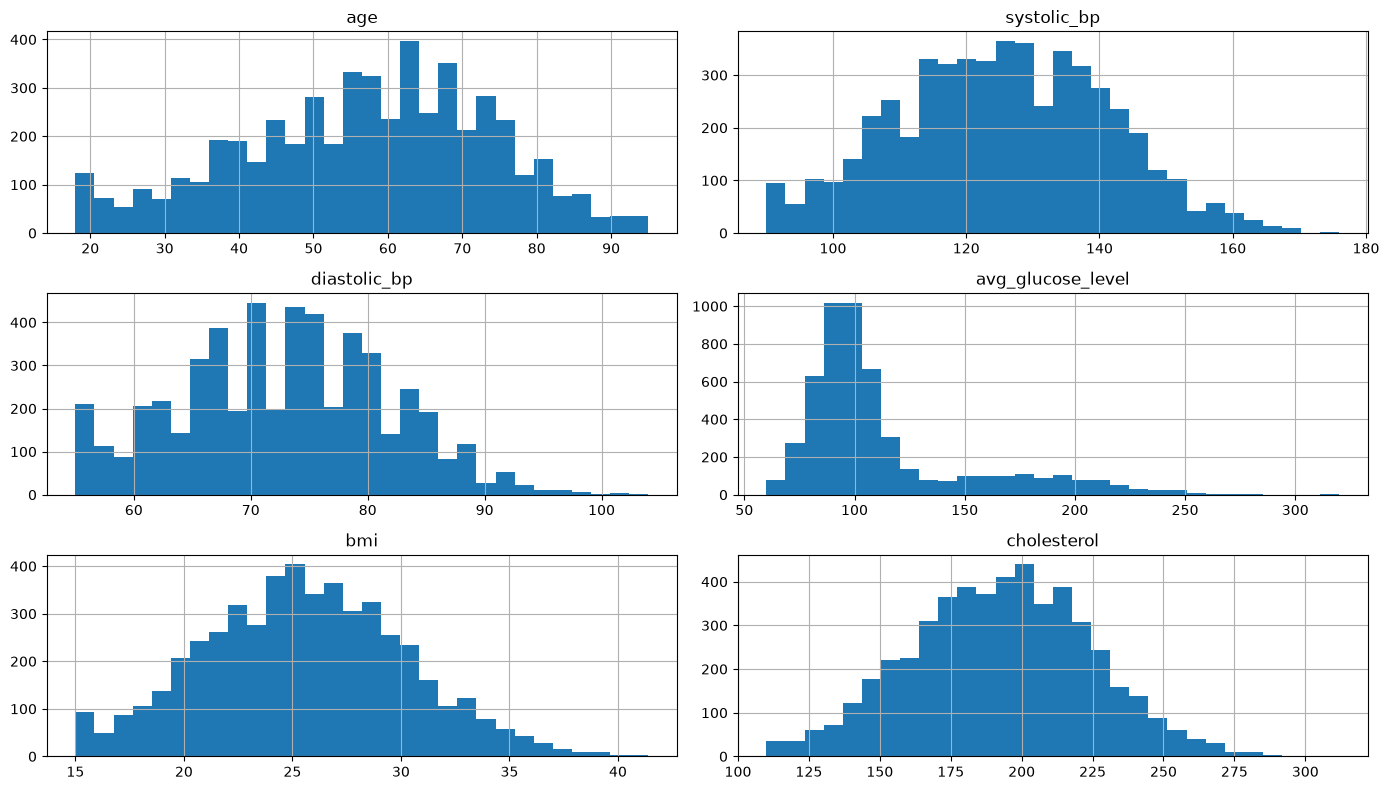

In [39]:
num_cols = ['age', 'systolic_bp', 'diastolic_bp',
            'avg_glucose_level', 'bmi', 'cholesterol']

df[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['patient_id', 'stroke'])
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

bmi_median = X_train['bmi'].median()
chol_median = X_train['cholesterol'].median()

for data in (X_train, X_test):
    data['bmi'] = data['bmi'].fillna(bmi_median)
    data['cholesterol'] = data['cholesterol'].fillna(chol_median)

print(X_train.isna().sum().sum(), X_test.isna().sum().sum()) 

0 0


stroke                 0      1
age                 46.8   66.9
systolic_bp        115.5  135.3
diastolic_bp        68.1   77.6
avg_glucose_level  103.2  123.5
bmi                 23.7   27.4
cholesterol        179.2  205.8


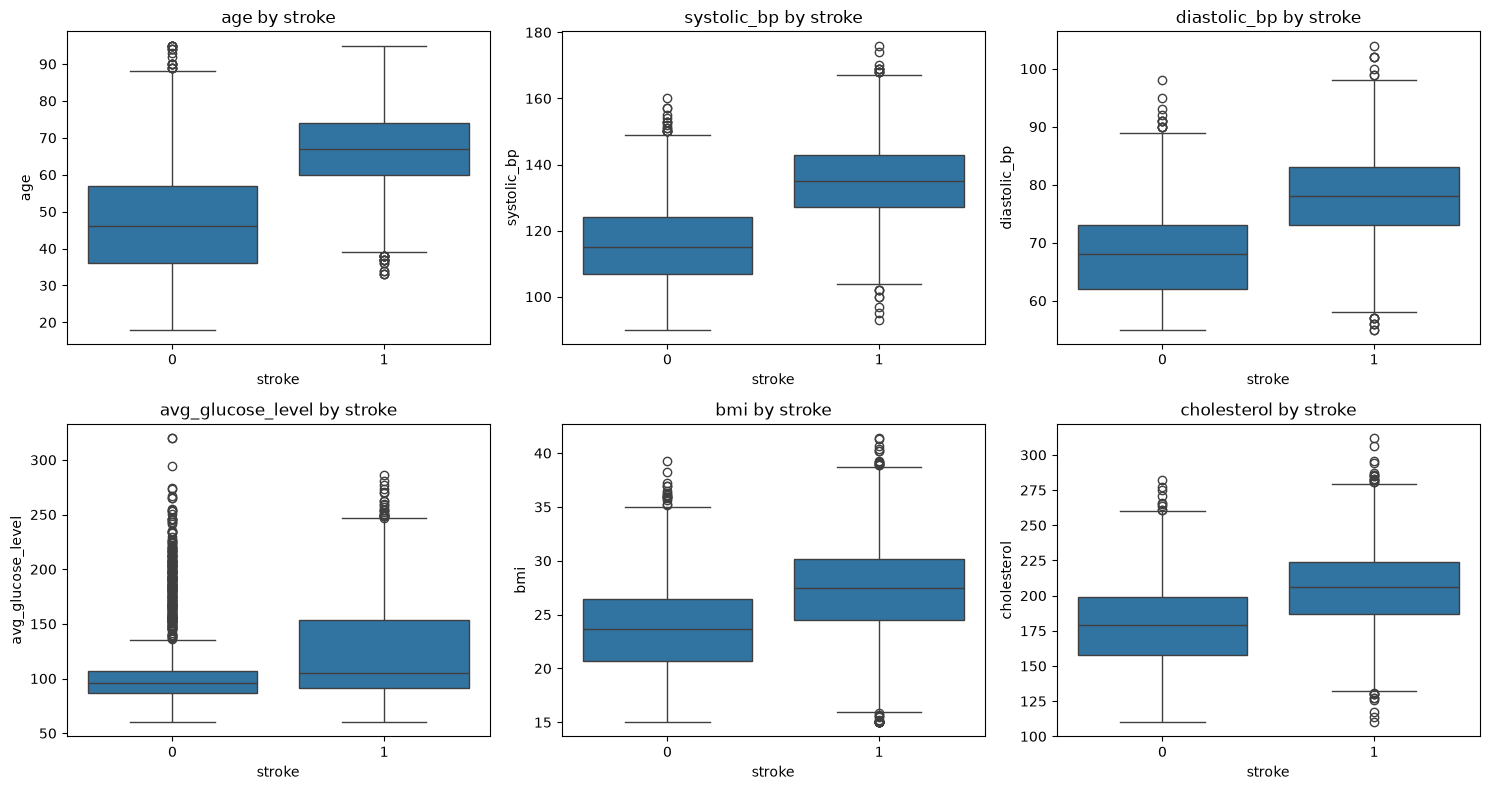

In [43]:
print(df.groupby('stroke')[num_cols].mean().round(1).T)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x='stroke', y=col, data=df, ax=ax)
    ax.set_title(f'{col} by stroke')
plt.tight_layout()
plt.show()

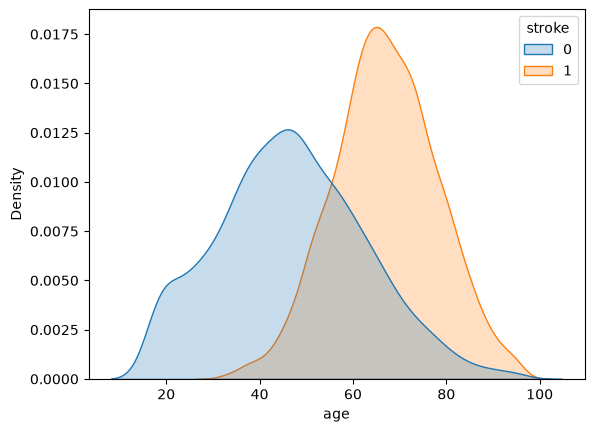

In [44]:
sns.kdeplot(data=df, x='age', hue='stroke', fill=True)
plt.show()

        count   mean
gender              
Female   2636  0.462
Male     2564  0.539 

                count   mean
smoking_status              
Current          1147  0.661
Former           1666  0.612
Never            2387  0.345 

                     count   mean
alcohol_consumption              
Heavy                 1100  0.603
Moderate              2040  0.469
Non-drinker           2060  0.476 

                   count   mean
physical_activity              
High                1516  0.380
Low                 1884  0.719
Moderate            1800  0.372 

               count   mean
work_type                  
Govt_job         652  0.449
Private         1966  0.380
Retired         1371  0.798
Self-employed    845  0.460
Student          139  0.000
Unemployed       227  0.335 

                count   mean
residence_type              
Rural            2464  0.504
Urban            2736  0.497 

              count   mean
hypertension              
0              3883  0.400
1       

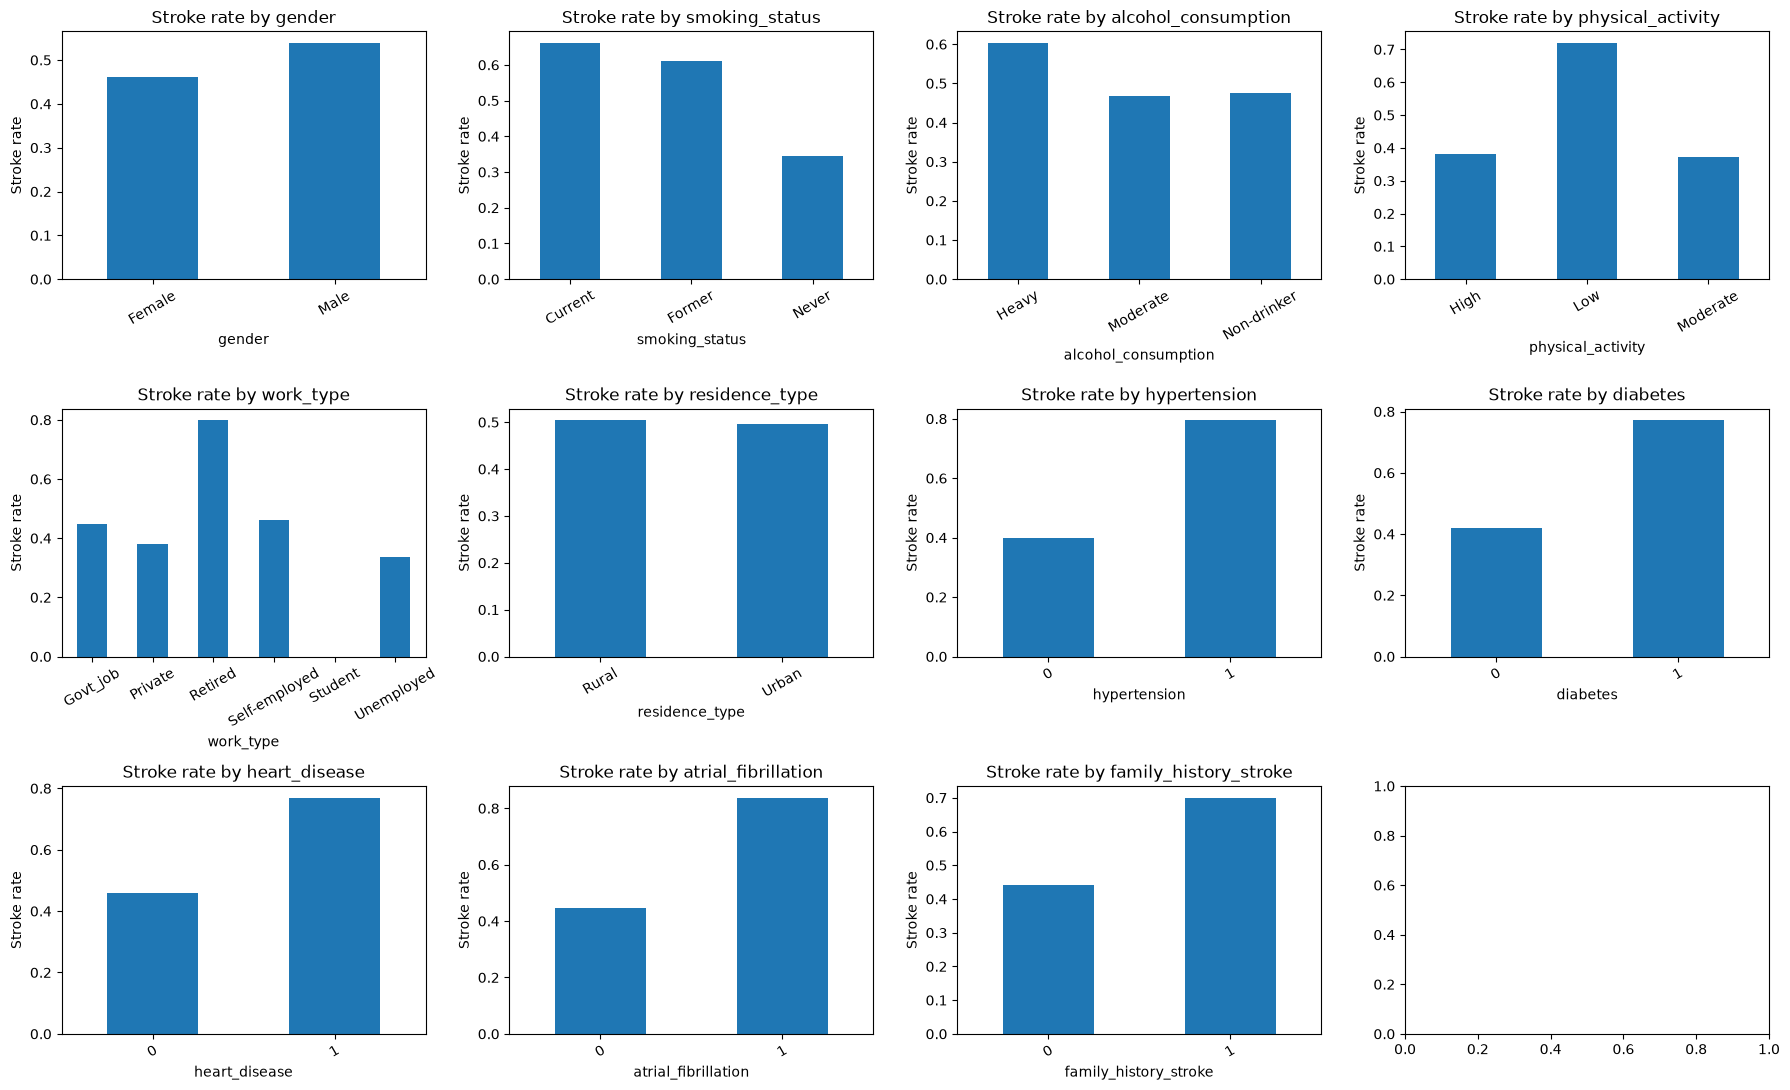

In [45]:
cat_cols = ['gender', 'smoking_status', 'alcohol_consumption',
            'physical_activity', 'work_type', 'residence_type',
            'hypertension', 'diabetes', 'heart_disease',
            'atrial_fibrillation', 'family_history_stroke']

# Stroke rate for each category
for col in cat_cols:
    print(df.groupby(col)['stroke'].agg(['count', 'mean']).round(3), '\n')

# Bar charts of stroke rate
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), cat_cols):
    df.groupby(col)['stroke'].mean().plot(kind='bar', ax=ax)
    ax.set_title(f'Stroke rate by {col}')
    ax.set_ylabel('Stroke rate')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

           count   mean
age_group              
18-30        414  0.000
31-45        895  0.079
46-60       1518  0.431
61-75       1696  0.769
76+          677  0.840


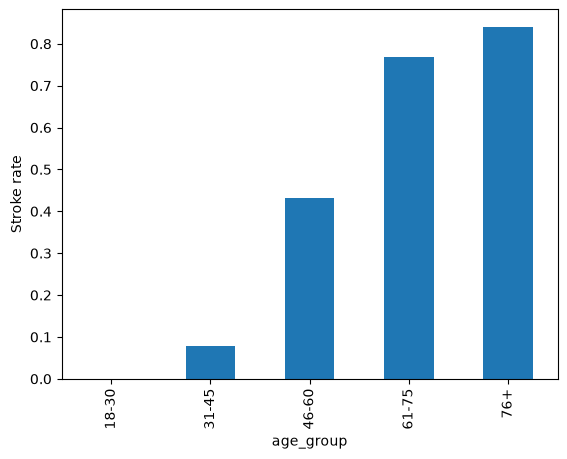

In [46]:
df['age_group'] = pd.cut(df['age'], [17, 30, 45, 60, 75, 100],
                         labels=['18-30', '31-45', '46-60', '61-75', '76+'])
print(df.groupby('age_group', observed=True)['stroke'].agg(['count', 'mean']).round(3))

df.groupby('age_group', observed=True)['stroke'].mean().plot(kind='bar')
plt.ylabel('Stroke rate')
plt.show()

In [49]:
df.loc[df['age_group']=='18-30']['stroke'].unique()

array([0])

systolic_bp              0.625055
age                      0.592509
diastolic_bp             0.529682
cholesterol              0.416884
bmi                      0.387616
hypertension             0.342709
diabetes                 0.296116
atrial_fibrillation      0.271483
avg_glucose_level        0.254100
family_history_stroke    0.215791
heart_disease            0.208145
Name: stroke, dtype: float64


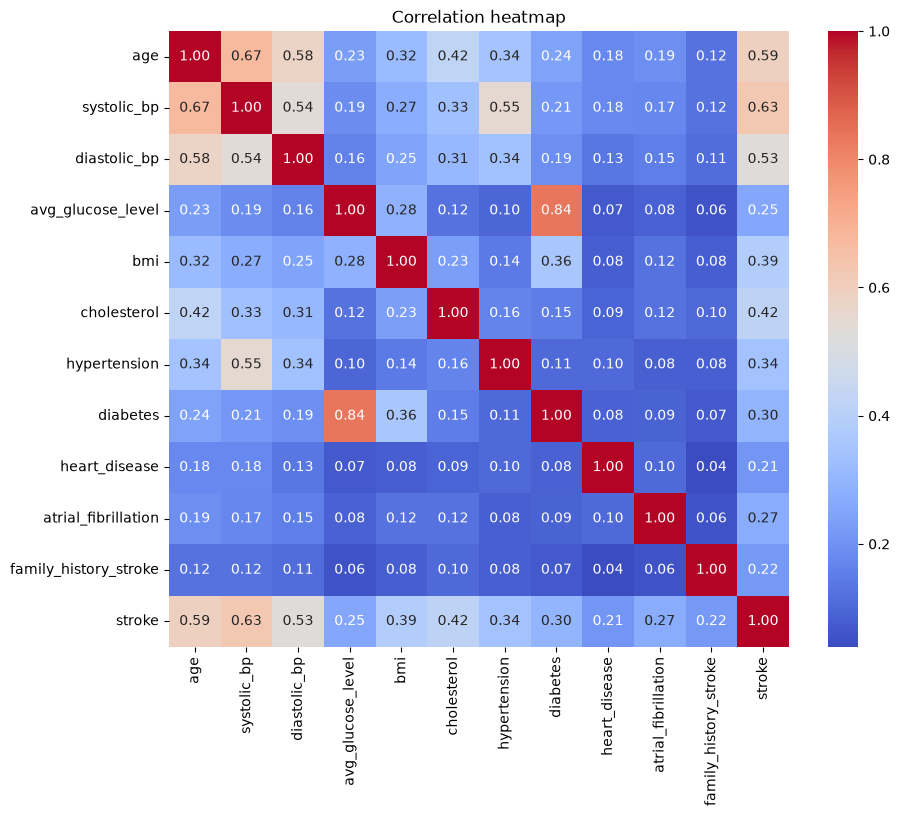

In [53]:
corr_cols = num_cols + ['hypertension', 'diabetes', 'heart_disease','atrial_fibrillation', 'family_history_stroke', 'stroke']

print(df[corr_cols].corr()['stroke'].drop('stroke').sort_values(ascending=False))

plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

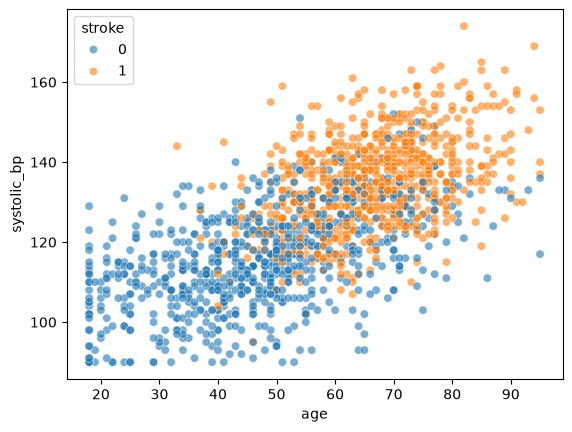

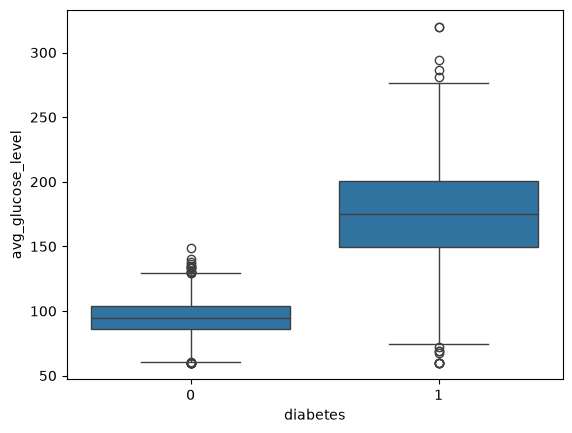

In [54]:
sns.scatterplot(data=df.sample(1500, random_state=1),
                x='age', y='systolic_bp', hue='stroke', alpha=0.6)
plt.show()

sns.boxplot(x='diabetes', y='avg_glucose_level', data=df)
plt.show()


In [55]:
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: {outliers} outliers')

age: 0 outliers
systolic_bp: 2 outliers
diastolic_bp: 11 outliers
avg_glucose_level: 765 outliers
bmi: 19 outliers
cholesterol: 14 outliers


In [56]:
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

print('BEFORE:', {c: count_outliers(X_train[c]) for c in num_cols})

# Cap at 1st/99th percentile of TRAIN, apply same caps to test
caps = {}
for col in ['systolic_bp', 'diastolic_bp', 'bmi', 'cholesterol']:
    lo, hi = X_train[col].quantile([0.01, 0.99])
    caps[col] = (lo, hi)
    X_train[col] = X_train[col].clip(lo, hi)
    X_test[col] = X_test[col].clip(lo, hi)

# Glucose: high values are the real diabetic group -> keep, add a flag
for data in (X_train, X_test):
    data['high_glucose'] = (data['avg_glucose_level'] > 126).astype(int)

print('AFTER :', {c: count_outliers(X_train[c]) for c in num_cols})

BEFORE: {'age': 0, 'systolic_bp': 1, 'diastolic_bp': 7, 'avg_glucose_level': 609, 'bmi': 22, 'cholesterol': 17}
AFTER : {'age': 0, 'systolic_bp': 0, 'diastolic_bp': 0, 'avg_glucose_level': 609, 'bmi': 0, 'cholesterol': 0}


In [58]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [60]:
import time
import joblib
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

models = {
    'Logistic Regression': (LogisticRegression(max_iter=3000),
                            {'C': [0.01, 0.1, 1, 10], 'penalty': ['l2']}),
    'KNN': (KNeighborsClassifier(),
            {'n_neighbors': [5, 9, 15, 25], 'weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42),
                      {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [1, 5, 20]}),
    'Random Forest': (RandomForestClassifier(random_state=42),
                      {'n_estimators': [100, 200], 'max_depth': [5, 10, None],
                       'min_samples_leaf': [1, 5]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=42),
                          {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1],
                           'max_depth': [2, 3]}),
    'SVM': (SVC(probability=True, random_state=42),
            {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}),
    'AdaBoost': (AdaBoostClassifier(random_state=42),
                 {'n_estimators': [50, 100, 200], 'learning_rate': [0.05, 0.1, 1.0]}),
}

In [61]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
best_models = {}

for name, (est, grid) in models.items():
    start = time.time()
    gs = GridSearchCV(est, grid, cv=cv, scoring='accuracy', n_jobs=-1)
    gs.fit(X_train, y_train)

    best = gs.best_estimator_
    pred = best.predict(X_test)

    rows.append({
        'Model': name,
        'CV Accuracy': round(gs.best_score_, 4),
        'Test Accuracy': round(accuracy_score(y_test, pred), 4),
        'Test F1': round(f1_score(y_test, pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, best.predict_proba(X_test)[:, 1]), 4),
        'Best Params': gs.best_params_
    })
    best_models[name] = best
    print(f'{name} done in {time.time() - start:.1f}s')

results = pd.DataFrame(rows).sort_values('CV Accuracy', ascending=False).reset_index(drop=True)
print(results.drop(columns='Best Params').to_string())
print(results[['Model', 'Best Params']].to_string())

c:\Users\bount\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Logistic Regression done in 5.6s
KNN done in 0.8s
Decision Tree done in 0.4s
Random Forest done in 6.6s
Gradient Boosting done in 6.6s


c:\Users\bount\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM done in 9.7s
AdaBoost done in 5.1s
                 Model  CV Accuracy  Test Accuracy  Test F1  Test ROC-AUC
0  Logistic Regression       0.8728         0.8779   0.8782        0.9499
1                  SVM       0.8716         0.8798   0.8804        0.9507
2    Gradient Boosting       0.8690         0.8644   0.8651        0.9455
3        Random Forest       0.8647         0.8596   0.8630        0.9440
4             AdaBoost       0.8647         0.8606   0.8612        0.9444
5                  KNN       0.8611         0.8615   0.8623        0.9374
6        Decision Tree       0.8312         0.8260   0.8241        0.8980
                 Model                                                    Best Params
0  Logistic Regression                                      {'C': 1, 'penalty': 'l2'}
1                  SVM                                 {'C': 0.1, 'kernel': 'linear'}
2    Gradient Boosting   {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
3        Random Forest  {

In [62]:
best_name = results.loc[0, 'Model']
print('Best model:', best_name)

joblib.dump(best_models[best_name], 'best_stroke_model.pkl')

# Save everything needed to prepare new data the same way
joblib.dump({
    'scaler': scaler,
    'columns': list(X_train.columns),
    'num_cols': num_cols,
    'bmi_median': bmi_median,
    'chol_median': chol_median,
    'caps': caps
}, 'preprocessing.pkl')

# Check it loads and works
loaded = joblib.load('best_stroke_model.pkl')
print('Reloaded test accuracy:', accuracy_score(y_test, loaded.predict(X_test)))

Best model: Logistic Regression
Reloaded test accuracy: 0.8778846153846154
